# Hirakud reservoir – weekly forecasting (`train.ipynb`)
Predicts the **change in `pct_full`** 1, 2 and 4 weeks ahead (7, 14, 28 days) and a low-storage warning.

Why weekly: the cleaned data is daily in 2013-2020 but effectively weekly before (forward-filled, ~70 % stale in 2010-12) and after (2023-25). One weekly resolution keeps every feature meaning the same thing in every year.

**v0.2 additions:** Mahanadi **river discharge** (Open-Meteo Flood API / GloFAS) at main-stem and tributary points, per-point upstream rain with travel-time lags, season-context features, **conformal prediction bands** (calibrated coverage), an HGB+Ridge blend chosen by CV, and an *oracle* experiment showing how much a perfect rain forecast could add.

Modelling notes
- Target = `pct_full(t+h) − pct_full(t)` (percentage points), directly comparable with the baselines.
- **No look-ahead:** the origin week must be observed; lags may use single-gap fills made from the past only. A test at the end proves the features are causal.
- Hyper-parameters, the weather/discharge variant, the blend decision and the conformal offsets all come from `TimeSeriesSplit` on training years only – never from the test set.
- **Rain forecasts:** Open-Meteo's archived forecasts start in ~2021 and only keep short lead times, so a model for 1-4 week horizons cannot be trained on them leak-free. We therefore do not use forecast inputs; the *oracle* section quantifies the ceiling instead (not deployable).

## 1. Config

In [149]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")   # tiny data: many OpenMP threads make gradient boosting far slower
from pathlib import Path
import json, warnings, itertools, time
import numpy as np
import pandas as pd
import requests
import joblib
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import r2_score

warnings.filterwarnings("ignore")

ROOT          = Path("..")
CLEAN_CSV     = ROOT / "data/processed/hirakud_clean.csv"
WEATHER_DIR   = ROOT / "data/weather"
DISCHARGE_DIR = ROOT / "data/discharge"
OUT_DIR       = ROOT / "outputs"
for d in (WEATHER_DIR, DISCHARGE_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

CUTOFF          = pd.Timestamp("2022-01-01")
HORIZONS        = (1, 2, 4)                 # weeks  -> 7, 14, 28 days
WARN_PERCENTILE = 20                        # low-storage threshold, from training data only
SEED            = 42
VERSION         = "0.2.0"
USE_LAG52       = True                      # pct_full 52 weeks ago (causal)
BACKTEST_YEARS  = [2022, 2023, 2024, 2025]    # strictly independent held-out years (tuning/variant frozen on <=2021)
MONSOON_MONTHS  = [6, 7, 8, 9, 10]
CONFORMAL_LEVEL = 0.80                      # target coverage of the prediction band

# Approximate upstream rain points of the Hirakud (Mahanadi) catchment
UPSTREAM = {
    "raipur":   (21.25, 81.63),   # Mahanadi/Seonath, Chhattisgarh plains
    "sihawa":   (20.55, 81.57),   # Mahanadi headwaters
    "bilaspur": (22.08, 82.15),   # Seonath/Hasdeo side
    "raigarh":  (21.90, 83.40),   # Ib / Mand catchment, just upstream of the dam
}
# River-discharge points snapped onto the main stem / tributaries (checked: mean flow in the 1000s of m3/s).
# The dam coordinate itself snaps onto a tiny stream (~9 m3/s), so it must NOT be used for discharge.
DISCHARGE_PTS = {
    "mahanadi_in":  (21.65, 83.40),   # main stem just upstream of the reservoir (reservoir inflow)
    "seorinarayan": (21.72, 82.59),   # main stem further upstream  (travel-time lead)
    "ib":           (21.85, 83.90),   # Ib tributary
    "arang":        (21.20, 81.97),   # upper Mahanadi
}

GRID = {"max_depth": [3, 4, 6], "learning_rate": [0.05, 0.1], "min_samples_leaf": [10, 20]}
np.random.seed(SEED)

## 2. Load the cleaned data

In [150]:
def load_clean(path=CLEAN_CSV):
    df = pd.read_csv(path, parse_dates=["date"])
    assert df["date"].is_monotonic_increasing, "dates not sorted"
    assert df["date"].is_unique, "duplicate dates"
    df["stale_value"] = df["stale_value"].astype(bool)
    # stale (carried-forward) readings carry no new information -> blank them. pct_full is NOT clipped at 100.
    df.loc[df["stale_value"], "pct_full"] = np.nan
    return df

clean = load_clean()
DAM_LAT, DAM_LON = clean["lat"].iloc[0], clean["lon"].iloc[0]
IMPLIED_CAPACITY = (clean["storage_bcm"] / clean["pct_full"] * 100).median()
print(clean.shape, clean.date.min().date(), "->", clean.date.max().date())
print(f"Stale rows blanked: {clean.pct_full.isna().sum()} | implied capacity ~ {IMPLIED_CAPACITY:.3f} bcm")

(4006, 8) 2010-01-01 -> 2025-07-10
Stale rows blanked: 1040 | implied capacity ~ 4.827 bcm


## 3. Weekly resolution (weeks end on Thursday, as in the CWC bulletin)

In [151]:
def to_weekly(df, verbose=False):
    """Weekly mean of non-stale pct_full on W-THU.
    pct_obs  : observed weeks only (NaN where no real reading)
    pct_fill : pct_obs with *single-week* gaps linearly interpolated (longer gaps stay NaN)"""
    s = df.set_index("date")["pct_full"].dropna()
    pct_obs = s.resample("W-THU").mean()
    isna = pct_obs.isna()
    run_id = (isna != isna.shift()).cumsum()
    gap_len = isna.groupby(run_id).transform("sum").where(isna, 0)      # length of the gap each NaN belongs to
    interp = pct_obs.interpolate(limit_area="inside")
    pct_fill = pct_obs.copy()
    fill_mask = isna & (gap_len == 1) & interp.notna()
    pct_fill[fill_mask] = interp[fill_mask]
    w = pd.DataFrame({"pct_obs": pct_obs, "pct_fill": pct_fill})
    if verbose:
        print(f"weeks: {len(w)} | observed: {w.pct_obs.notna().mean():.1%} | after single-gap fill: {w.pct_fill.notna().mean():.1%}"
              f" | usable weeks: {w.pct_fill.notna().sum()}")
    return w

weekly = to_weekly(clean, verbose=True)
weekly.tail()

weeks: 810 | observed: 95.9% | after single-gap fill: 99.1% | usable weeks: 803


,pct_obs,pct_fill
date,,
2025-06-12,20.16,20.16
2025-06-19,17.55,17.55
2025-06-26,16.74,16.74
2025-07-03,16.53,16.53
2025-07-10,25.96,25.96


## 4. Weather and river discharge (Open-Meteo, cached)
- Archive API: daily rain, ET0, temperature (dam + upstream points) → `data/weather/`.
- Flood API (GloFAS reanalysis): daily `river_discharge` on the Mahanadi main stem and the Ib → `data/discharge/`.
Rolling windows **end on the week-end date** so nothing from the future is used.

In [152]:
W_START = (clean.date.min() - pd.Timedelta(days=120)).strftime("%Y-%m-%d")     # warm-up for 13-week windows
W_END   = clean.date.max().strftime("%Y-%m-%d")

def fetch_weather(name, lat, lon):
    f = WEATHER_DIR / f"{name}.csv"
    if f.exists():
        return pd.read_csv(f, parse_dates=["date"]).set_index("date")
    r = requests.get("https://archive-api.open-meteo.com/v1/archive", timeout=60, params=dict(
        latitude=lat, longitude=lon, start_date=W_START, end_date=W_END, timezone="Asia/Kolkata",
        daily="precipitation_sum,et0_fao_evapotranspiration,temperature_2m_mean"))
    r.raise_for_status()
    d = pd.DataFrame(r.json()["daily"]).rename(columns={
        "time": "date", "precipitation_sum": "rain", "et0_fao_evapotranspiration": "et0", "temperature_2m_mean": "temp"})
    d["date"] = pd.to_datetime(d["date"]); d.to_csv(f, index=False); time.sleep(1)
    return d.set_index("date")

def fetch_discharge(name, lat, lon):
    f = DISCHARGE_DIR / f"{name}.csv"
    if f.exists():
        return pd.read_csv(f, parse_dates=["date"]).set_index("date")["discharge"]
    r = requests.get("https://flood-api.open-meteo.com/v1/flood", timeout=60, params=dict(
        latitude=lat, longitude=lon, start_date=W_START, end_date=W_END, daily="river_discharge"))
    r.raise_for_status()
    d = pd.DataFrame(r.json()["daily"]).rename(columns={"time": "date", "river_discharge": "discharge"})
    d["date"] = pd.to_datetime(d["date"]); d.to_csv(f, index=False); time.sleep(1)
    return d.set_index("date")["discharge"]

points = {"dam": (DAM_LAT, DAM_LON), **UPSTREAM}
wx_raw = {n: fetch_weather(n, la, lo) for n, (la, lo) in points.items()}
qd_raw = {n: fetch_discharge(n, la, lo) for n, (la, lo) in DISCHARGE_PTS.items()}
for n, d in wx_raw.items():
    print(f"rain    {n:13s} rows={len(d)} missing={int(d.isna().sum().sum())}")
for n, d in qd_raw.items():
    print(f"flow    {n:13s} rows={len(d)} missing={int(d.isna().sum())} mean={d.mean():8.0f} m3/s  max={d.max():8.0f}")

rain    dam           rows=5790 missing=0
rain    raipur        rows=5790 missing=0
rain    sihawa        rows=5790 missing=0
rain    bilaspur      rows=5790 missing=0
rain    raigarh       rows=5790 missing=0
flow    mahanadi_in   rows=5790 missing=0 mean=    1159 m3/s  max=   19186
flow    seorinarayan  rows=5790 missing=0 mean=     785 m3/s  max=   19186
flow    ib            rows=5790 missing=0 mean=     211 m3/s  max=    1651
flow    arang         rows=5790 missing=0 mean=     163 m3/s  max=    9749


In [153]:
def add_weather(wx_daily):
    """Daily weather -> features on W-THU week ends (windows end on the week-end date)."""
    d = wx_daily.asfreq("D")
    d[["rain", "et0", "temp"]] = d[["rain", "et0", "temp"]].ffill(limit=3)
    season = (d.index - pd.DateOffset(months=5)).year               # 1 June starts a new 'monsoon year'
    return pd.DataFrame({
        "rain_1w":     d["rain"].rolling(7).sum(),
        "rain_4w":     d["rain"].rolling(28).sum(),
        "rain_13w":    d["rain"].rolling(91).sum(),
        "rain_season": d["rain"].groupby(season).cumsum(),          # cumulative rain since 1 June
        "et0_4w":      d["et0"].rolling(28).sum(),
        "temp_1w":     d["temp"].rolling(7).mean(),
    })

def add_upstream_lags(wx_dict):
    """Each upstream point separately, with travel-time lags (rain in Chhattisgarh reaches the dam days-weeks later)."""
    out = {}
    for n in UPSTREAM:
        r = wx_dict[n]["rain"].asfreq("D").ffill(limit=3)
        r7 = r.rolling(7).sum()
        out[f"{n}_rain1w"] = r7
        out[f"{n}_rain1w_l1"] = r7.shift(7)
        out[f"{n}_rain1w_l2"] = r7.shift(14)
        out[f"{n}_rain4w"] = r.rolling(28).sum()
    return pd.DataFrame(out)

def add_discharge(qd_dict):
    """River discharge features (log scale): level, 7-day max, 1- and 2-week change, per point."""
    out = {}
    for n, s in qd_dict.items():
        q = np.log1p(s.asfreq("D").ffill(limit=3))
        out[f"q_{n}"] = q
        out[f"q7max_{n}"] = q.rolling(7).max()
        out[f"dq1_{n}"] = q - q.shift(7)
        out[f"dq2_{n}"] = q - q.shift(14)
    return pd.DataFrame(out)

def weather_variant(name, wx=None, qd=None):
    """name = parts joined with '+': dam | upstream_lag | discharge | none"""
    wx = wx_raw if wx is None else wx
    qd = qd_raw if qd is None else qd
    if name == "none":
        return None
    parts = []
    for p in name.split("+"):
        if p == "dam":           parts.append(add_weather(wx["dam"]))
        elif p == "upstream_lag": parts.append(add_upstream_lags(wx))
        elif p == "discharge":   parts.append(add_discharge(qd))
        else: raise ValueError(p)
    return pd.concat(parts, axis=1)

VARIANTS = ["none", "dam", "upstream_lag", "discharge", "dam+discharge", "upstream_lag+discharge"]

## 5. Features and targets

In [154]:
def make_features(weekly, wx=None, use_lag52=USE_LAG52):
    f = pd.DataFrame(index=weekly.index)
    f["pct_now"] = weekly["pct_obs"]                         # origin must be an actually-observed week
    for k in (1, 2, 4):
        f[f"d{k}w"] = weekly["pct_obs"] - weekly["pct_fill"].shift(k)    # lags may use causal single-gap fill
    if use_lag52:
        f["pct_52w_ago"] = weekly["pct_fill"].shift(52)
    if wx is not None:
        f = f.join(wx.reindex(weekly.index))
    woy = weekly.index.isocalendar().week.astype(int).values
    f["woy_sin"] = np.sin(2 * np.pi * woy / 52.18)
    f["woy_cos"] = np.cos(2 * np.pi * woy / 52.18)
    return f

def make_targets(weekly, horizons=HORIZONS, use_observed_only=True):
    # Strictly genuinely observed target values: future level at t+h must be strictly observed in pct_obs.
    # Never treat interpolated future values as ground truth for training or evaluation.
    series = weekly["pct_obs"] if use_observed_only else weekly["pct_fill"]
    return pd.DataFrame({h: series.shift(-h) - weekly["pct_obs"] for h in horizons})

targets = make_targets(weekly, use_observed_only=True)
targets_fill = make_targets(weekly, use_observed_only=False)
feats = {v: make_features(weekly, weather_variant(v)) for v in VARIANTS}
print({v: f.shape[1] for v, f in feats.items()}, "features per variant")
feats["dam+discharge"].dropna().tail(3).T.head(14)

{'none': 7, 'dam': 13, 'upstream_lag': 23, 'discharge': 23, 'dam+discharge': 29, 'upstream_lag+discharge': 39} features per variant


date,2025-06-26,2025-07-03,2025-07-10
pct_now,16.740000,16.530000,25.960000
d1w,-0.810000,-0.210000,9.430000
d2w,-3.420000,-1.020000,9.220000
d4w,-7.970000,-6.440000,5.800000
pct_52w_ago,14.550000,16.330000,15.890000
rain_1w,88.700000,217.200000,161.800000
rain_4w,176.500000,379.800000,537.900000
rain_13w,251.200000,466.300000,625.000000
rain_season,173.800000,391.000000,552.800000
et0_4w,139.640000,118.290000,96.950000


## 6. Time split (target dates never cross the cut-off)

In [155]:
def split_time(features, targets, h, cutoff=CUTOFF):
    ok = features["pct_now"].notna() & targets[h].notna()
    X, y = features[ok], targets.loc[ok, h]
    train = X.index < cutoff - pd.Timedelta(weeks=h)
    test  = X.index >= cutoff
    return X[train], y[train], X[test], y[test]

for h in HORIZONS:
    Xtr, ytr, Xte, yte = split_time(feats["dam"], targets, h)
    print(f"h={h}w  train={len(Xtr)} ({Xtr.index.min().date()}..{Xtr.index.max().date()})  test={len(Xte)} ({Xte.index.min().date()}..{Xte.index.max().date()})")

h=1w  train=582 (2010-01-07..2021-12-23)  test=164 (2022-01-06..2025-07-03)
h=2w  train=580 (2010-01-07..2021-12-16)  test=162 (2022-01-06..2025-06-26)
h=4w  train=577 (2010-01-07..2021-12-02)  test=160 (2022-01-06..2025-06-12)


## 7. Baselines (persistence and seasonal, computed from training data only)

In [156]:
def seasonal_table(X_train, y_train):
    woy = X_train.index.isocalendar().week.astype(int)
    return y_train.groupby(woy.values).mean()

def seasonal_predict(table, index):
    woy = index.isocalendar().week.astype(int)
    return pd.Series(woy.map(table).fillna(0.0).values, index=index)

def season_mask(index):
    m = index.month.isin(MONSOON_MONTHS)
    return {"all": np.ones(len(index), bool), "monsoon": m, "dry": ~m}

def mae_by_season(y, pred, index):
    out = {}
    for k, m in season_mask(index).items():
        out[k] = float(np.mean(np.abs(np.asarray(y)[m] - np.asarray(pred)[m]))) if m.sum() else np.nan
    return out

def baselines(variant="dam"):
    rows = []
    for h in HORIZONS:
        Xtr, ytr, Xte, yte = split_time(feats[variant], targets, h)
        pers = mae_by_season(yte, np.zeros(len(yte)), Xte.index)
        seas = mae_by_season(yte, seasonal_predict(seasonal_table(Xtr, ytr), Xte.index), Xte.index)
        rows.append({"h_weeks": h, "n_test": len(yte),
                     **{f"persist_{k}": v for k, v in pers.items()}, **{f"seasonal_{k}": v for k, v in seas.items()}})
    return pd.DataFrame(rows).set_index("h_weeks").round(2)

baseline_table = baselines()
baseline_table

,n_test,persist_all,persist_monsoon,persist_dry,seasonal_all,seasonal_monsoon,seasonal_dry
h_weeks,,,,,,,
1,164,3.79,5.55,2.70,2.62,5.27,0.97
2,162,6.85,9.27,5.34,3.41,6.31,1.61
4,160,12.94,16.86,10.65,4.24,7.13,2.55


## 8. Models
- Median model: HistGradientBoosting (absolute error), optionally **blended 50/50 with Ridge** if that lowers CV error.
- Bands: (a) HGB quantile models (10 % / 90 %), (b) **conformal bands** = median ± out-of-fold residual quantiles, computed separately for monsoon and dry season, so the stated coverage is actually achieved.
- Everything is tuned with `TimeSeriesSplit` (gap = horizon) on training years only.

In [157]:
def hgb(loss="absolute_error", quantile=None, **p):
    return HistGradientBoostingRegressor(loss=loss, quantile=quantile, max_iter=200, random_state=SEED, **p)

def ridge_model():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10.0))

def sanitize_for_hgb(X):
    if isinstance(X, pd.DataFrame):
        all_nan = X.isna().all()
        if all_nan.any():
            X = X.copy()
            X.loc[:, all_nan] = 0.0
    return X

def fit_median(X, y, params, blend=False):
    X = sanitize_for_hgb(X)
    return {"hgb": hgb(**params).fit(X, y), "ridge": ridge_model().fit(X, y) if blend else None, "blend": blend}

def predict_median(m, X):
    X = sanitize_for_hgb(X)
    p = m["hgb"].predict(X)
    return 0.5 * p + 0.5 * m["ridge"].predict(X) if m["blend"] else p

def oof_residuals(X, y, h, params, blend, n_splits=5):
    """Out-of-fold residuals (time-ordered, gap=h) of the median predictor."""
    res = []
    for tr, va in TimeSeriesSplit(n_splits=n_splits, gap=h).split(X):
        m = fit_median(X.iloc[tr], y.iloc[tr], params, blend)
        res.append(pd.Series(y.iloc[va].values - predict_median(m, X.iloc[va]), index=X.index[va]))
    return pd.concat(res)

def tune_hgb(X, y, h):
    best = (np.inf, None)
    for md_, lr, leaf in itertools.product(GRID["max_depth"], GRID["learning_rate"], GRID["min_samples_leaf"]):
        p = dict(max_depth=md_, learning_rate=lr, min_samples_leaf=leaf)
        s = oof_residuals(X, y, h, p, False).abs().mean()
        if s < best[0]:
            best = (float(s), p)
    return best

def conformal_offsets(res, level=CONFORMAL_LEVEL):
    """(low, high) additive offsets on the median, per season, from out-of-fold residuals."""
    a = (1 - level) / 2
    pooled = (float(res.quantile(a)), float(res.quantile(1 - a)))
    out = {}
    for name, mask in (("monsoon", res.index.month.isin(MONSOON_MONTHS)), ("dry", ~res.index.month.isin(MONSOON_MONTHS))):
        r = res[mask]
        out[name] = (float(r.quantile(a)), float(r.quantile(1 - a))) if len(r) >= 30 else pooled
    return out

def apply_conformal(offsets, med, index):
    mons = index.month.isin(MONSOON_MONTHS)
    lo = med + np.where(mons, offsets["monsoon"][0], offsets["dry"][0])
    hi = med + np.where(mons, offsets["monsoon"][1], offsets["dry"][1])
    return lo, hi

def fit_quantiles(X, y, params):
    X = sanitize_for_hgb(X)
    return {"q10": hgb(loss="quantile", quantile=0.10, **params).fit(X, y),
            "q90": hgb(loss="quantile", quantile=0.90, **params).fit(X, y)}

In [158]:
# Tune every weather/discharge variant on training data only (CV), for every horizon
TUNING_CACHE = OUT_DIR / "tuning_cache.joblib"
if TUNING_CACHE.exists():
    tuning = joblib.load(TUNING_CACHE)
    print(f"Loaded hyperparameter tuning from {TUNING_CACHE} ({len(tuning)} entries)")
else:
    tuning = {}
    t0 = time.time()
    for v in VARIANTS:
        for h in HORIZONS:
            Xtr, ytr, _, _ = split_time(feats[v], targets, h)
            score, params = tune_hgb(Xtr, ytr, h)
            blend_score = float(oof_residuals(Xtr, ytr, h, params, True).abs().mean())
            ridge_only = float(np.mean([np.mean(np.abs(ytr.iloc[va] - ridge_model().fit(Xtr.iloc[tr], ytr.iloc[tr]).predict(Xtr.iloc[va])))
                                        for tr, va in TimeSeriesSplit(n_splits=5, gap=h).split(Xtr)]))
            tuning[(v, h)] = {"cv_mae": score, "params": params, "blend_cv_mae": blend_score, "ridge_cv_mae": ridge_only,
                              "use_blend": blend_score < score}
        print(f"  {v:24s} done ({time.time() - t0:.0f}s)", flush=True)
    joblib.dump(tuning, TUNING_CACHE)

cv_table = pd.DataFrame({(v, h): {"HGB cv MAE": t["cv_mae"], "HGB+Ridge cv MAE": t["blend_cv_mae"], "Ridge cv MAE": t["ridge_cv_mae"], "blend?": t["use_blend"]}
                         for (v, h), t in tuning.items()}).T
cv_table.index.names = ["variant", "h_weeks"]
cv_table

Loaded hyperparameter tuning from ../outputs/tuning_cache.joblib (18 entries)


HGB cv MAE HGB+Ridge cv MAE Ridge cv MAE blend?
variant                h_weeks                                                
none                   1         2.137591         2.274996       2.7025  False
                       2         3.226572         3.579576     4.519113  False
                       4         4.814542         5.208365     7.007398  False
dam                    1         2.060377         2.145201     2.503392  False
                       2          3.29385         3.450213     4.093656  False
                       4          4.80247         4.953948     6.026751  False
upstream_lag           1         2.084776         2.234428     2.621852  False
                       2         3.271671         3.560441     4.269036  False
                       4           4.8319         5.147565     6.432276  False
discharge              1         2.120787         2.195819     2.518591  False
                       2         3.219395         3.453871     4.098206  False
                       4         4.865348         5.072644     6.211117  False
dam+discharge          1          2.09841         2.200261     2.547221  False
                       2         3.281619         3.493068     4.156387  False
                       4         4.968069         5.037828     6.041975  False
upstream_lag+discharge 1         2.126351         2.234809     2.658437  False
                       2         3.334972          3.57582     4.239911  False
                       4         4.906967         5.199885     6.335757  False

In [159]:
# Variant is picked by mean CV MAE (of the better of HGB / blend) across horizons – training years only, not the test set
def best_cv(v, h): return min(tuning[(v, h)]["cv_mae"], tuning[(v, h)]["blend_cv_mae"])
variant_cv = {v: float(np.mean([best_cv(v, h) for h in HORIZONS])) for v in VARIANTS}
BEST_VARIANT = min(variant_cv, key=variant_cv.get)
print({k: round(v, 3) for k, v in variant_cv.items()})
print("Chosen variant:", BEST_VARIANT)

{'none': 3.393, 'dam': 3.386, 'upstream_lag': 3.396, 'discharge': 3.402, 'dam+discharge': 3.449, 'upstream_lag+discharge': 3.456}
Chosen variant: dam


## 9. Evaluation on the test period (2022 →)

In [160]:
def evaluate_variant(v):
    res = {}
    for h in HORIZONS:
        Xtr, ytr, Xte, yte = split_time(feats[v], targets, h)
        t = tuning[(v, h)]
        med_m = fit_median(Xtr, ytr, t["params"], t["use_blend"])
        med = predict_median(med_m, Xte)
        qm = fit_quantiles(Xtr, ytr, t["params"])
        q = np.sort(np.column_stack([qm["q10"].predict(Xte), med, qm["q90"].predict(Xte)]), axis=1)
        off = conformal_offsets(oof_residuals(Xtr, ytr, h, t["params"], t["use_blend"]))
        clo, chi = apply_conformal(off, med, Xte.index)
        seas = seasonal_predict(seasonal_table(Xtr, ytr), Xte.index)
        y = yte.values
        res[h] = dict(med_model=med_m, quantile_models=qm, offsets=off, X_test=Xte, y_test=yte, med=med, q=q, c_lo=clo, c_hi=chi,
                      seasonal=seas, model_mae=mae_by_season(yte, med, Xte.index), seasonal_mae=mae_by_season(yte, seas, Xte.index),
                      persist_mae=mae_by_season(yte, np.zeros(len(yte)), Xte.index),
                      cov_quantile=float(((y >= q[:, 0]) & (y <= q[:, 2])).mean()),
                      cov_conformal=float(((y >= clo) & (y <= chi)).mean()))
    return res

results = {v: evaluate_variant(v) for v in VARIANTS}

rows = []
for v in VARIANTS:
    for h in HORIZONS:
        r = results[v][h]
        rows.append({"variant": v, "h_weeks": h, "blend": tuning[(v, h)]["use_blend"],
                     "MAE_all": r["model_mae"]["all"], "MAE_monsoon": r["model_mae"]["monsoon"], "MAE_dry": r["model_mae"]["dry"],
                     "seas_all": r["seasonal_mae"]["all"], "seas_monsoon": r["seasonal_mae"]["monsoon"], "seas_dry": r["seasonal_mae"]["dry"],
                     "skill_all": 1 - r["model_mae"]["all"] / r["seasonal_mae"]["all"],
                     "skill_monsoon": 1 - r["model_mae"]["monsoon"] / r["seasonal_mae"]["monsoon"],
                     "skill_dry": 1 - r["model_mae"]["dry"] / r["seasonal_mae"]["dry"],
                     "cov_quantile": r["cov_quantile"], "cov_conformal": r["cov_conformal"]})
eval_table = pd.DataFrame(rows).set_index(["variant", "h_weeks"])
eval_table.round(3)

blend  MAE_all  MAE_monsoon  MAE_dry  \
variant                h_weeks                                         
none                   1        False    2.400        4.705    0.962   
                       2        False    2.921        5.266    1.467   
                       4        False    3.726        6.437    2.142   
dam                    1        False    2.210        4.340    0.882   
                       2        False    3.127        5.783    1.480   
                       4        False    4.357        6.876    2.886   
upstream_lag           1        False    2.363        4.796    0.846   
                       2        False    3.154        6.057    1.355   
                       4        False    3.851        6.719    2.175   
discharge              1        False    2.296        4.631    0.840   
                       2        False    3.098        5.827    1.407   
                       4        False    4.089        6.995    2.391   
dam+discharge          1        False    2.299        4.631    0.843   
                       2        False    3.137        5.888    1.432   
                       4        False    4.422        7.415    2.673   
upstream_lag+discharge 1        False    2.310        4.709    0.814   
                       2        False    3.103        5.928    1.351   
                       4        False    4.133        7.244    2.315   

                                seas_all  seas_monsoon  seas_dry  skill_all  \
variant                h_weeks                                                
none                   1           2.621         5.272     0.967      0.084   
                       2           3.409         6.308     1.611      0.143   
                       4           4.238         7.134     2.546      0.121   
dam                    1           2.621         5.272     0.967      0.157   
                       2           3.409         6.308     1.611      0.083   
                       4           4.238         7.134     2.546     -0.028   
upstream_lag           1           2.621         5.272     0.967      0.098   
                       2           3.409         6.308     1.611      0.075   
                       4           4.238         7.134     2.546      0.091   
discharge              1           2.621         5.272     0.967      0.124   
                       2           3.409         6.308     1.611      0.091   
                       4           4.238         7.134     2.546      0.035   
dam+discharge          1           2.621         5.272     0.967      0.123   
                       2           3.409         6.308     1.611      0.080   
                       4           4.238         7.134     2.546     -0.043   
upstream_lag+discharge 1           2.621         5.272     0.967      0.118   
                       2           3.409         6.308     1.611      0.090   
                       4           4.238         7.134     2.546      0.025   

                                skill_monsoon  skill_dry  cov_quantile  \
variant                h_weeks                                           
none                   1                0.108      0.005         0.659   
                       2                0.165      0.090         0.630   
                       4                0.098      0.159         0.588   
dam                    1                0.177      0.088         0.616   
                       2                0.083      0.081         0.525   
                       4                0.036     -0.133         0.481   
upstream_lag           1                0.090      0.125         0.579   
                       2                0.040      0.159         0.506   
                       4                0.058      0.146         0.506   
discharge              1                0.122      0.131         0.616   
                       2                0.076      0.127         0.617   
                       4                0.019   

In [161]:
# Monsoon MAE by variant (informational – the variant was chosen on CV, not on this table)
monsoon_cmp = eval_table["MAE_monsoon"].unstack("variant").round(2)
monsoon_cmp["seasonal"] = eval_table.xs("none", level="variant")["seas_monsoon"].round(2)
print("Test monsoon MAE (pct-points) by variant:"); display(monsoon_cmp)
print(f"Chosen variant {BEST_VARIANT}: skill vs seasonal")
display(eval_table.loc[BEST_VARIANT][["skill_all", "skill_monsoon", "skill_dry", "cov_quantile", "cov_conformal"]].round(3))
for h in HORIZONS:
    s = eval_table.loc[(BEST_VARIANT, h), "skill_monsoon"]
    if s <= 0:
        print(f"NOTE: h={h}w monsoon skill vs seasonal baseline is {s:.2f} (<= 0) – the model does not beat the seasonal baseline there.")

Test monsoon MAE (pct-points) by variant:


variant,dam,dam+discharge,discharge,none,upstream_lag,upstream_lag+discharge,seasonal
h_weeks,,,,,,,
1,4.34,4.63,4.63,4.70,4.80,4.71,5.27
2,5.78,5.89,5.83,5.27,6.06,5.93,6.31
4,6.88,7.42,7.00,6.44,6.72,7.24,7.13


Chosen variant dam: skill vs seasonal


,skill_all,skill_monsoon,skill_dry,cov_quantile,cov_conformal
h_weeks,,,,,
1,0.157,0.177,0.088,0.616,0.774
2,0.083,0.083,0.081,0.525,0.784
4,-0.028,0.036,-0.133,0.481,0.738


## 9b. Oracle experiment – how much could a perfect rain forecast add?
Adds the **realised** rain of the next *h* weeks (dam + upstream mean) as a feature. This is **not deployable** (it uses the future); it only measures the ceiling that real rain forecasts could approach, using the same tuned hyper-parameters.

In [162]:
rain_all = sum(wx_raw[n]["rain"].asfreq("D").interpolate(limit=3) for n in points) / len(points)
oracle_rows = []
for h in HORIZONS:
    fut = rain_all.rolling(7 * h).sum().shift(-7 * h)           # rain over (t, t+h weeks]
    Xo = feats[BEST_VARIANT].copy(); Xo["ORACLE_future_rain"] = fut.reindex(Xo.index)
    Xtr, ytr, Xte, yte = split_time(Xo, targets, h)
    m = fit_median(Xtr, ytr, tuning[(BEST_VARIANT, h)]["params"], False)
    mae = mae_by_season(yte, predict_median(m, Xte), Xte.index)
    base = results[BEST_VARIANT][h]["model_mae"]
    oracle_rows.append({"h_weeks": h, "MAE_all": mae["all"], "MAE_monsoon": mae["monsoon"],
                        "real_model_MAE_all": base["all"], "real_model_MAE_monsoon": base["monsoon"],
                        "seasonal_MAE_monsoon": results[BEST_VARIANT][h]["seasonal_mae"]["monsoon"]})
oracle_table = pd.DataFrame(oracle_rows).set_index("h_weeks")
print("ORACLE (uses future rain – upper bound, not deployable):")
oracle_table.round(2)

ORACLE (uses future rain – upper bound, not deployable):


,MAE_all,MAE_monsoon,real_model_MAE_all,real_model_MAE_monsoon,seasonal_MAE_monsoon
h_weeks,,,,,
1,2.09,4.06,2.21,4.34,5.27
2,3.00,5.40,3.13,5.78,6.31
4,3.52,5.52,4.36,6.88,7.13


## 9c. Genuinely observed target evaluation & the three baselines (Priority 1)
1. **Target interpolation audit:** While the origin date $t$ is strictly observed, target date $t+h$ may occasionally fall on an interpolated single-week gap. We evaluate accuracy on **strictly genuinely observed target dates** separately.
2. **Three-baseline comparison:**
   - **Zero Change ($\Delta = 0$):** Assumes reservoir storage does not change over the horizon.
   - **Seasonal Climatology:** Historical mean change for week-of-year from training data.
   - **Rate / Trend Persistence ($\hat{\Delta}_{t, t+h} = y_t - y_{t-h}$):** Extrapolates the preceding $h$-week change forward.

In [163]:
# Identify strictly observed targets in test set
test_mask = clean.set_index("date")["pct_full"].dropna().resample("W-THU").mean()

def evaluate_observed_vs_all_and_baselines(variant=BEST_VARIANT):
    records_cmp = []
    records_baselines = []
    
    for h in HORIZONS:
        r = results[variant][h]
        df_test = r["X_test"].copy()
        y_obs = r["y_test"].values
        pred_obs = r["med"]
        seas_obs = r["seasonal"].values
        lo_obs, hi_obs = r["c_lo"], r["c_hi"]
        
        # 1. Target Audit: Compare strictly observed target evaluation against all-weeks (with single-gap interpolation)
        y_fill_series = targets_fill[h].loc[df_test.index.min():df_test.index.max()].dropna()
        X_fill = feats[variant].loc[y_fill_series.index]
        pred_fill = predict_median(r["med_model"], X_fill)
        seas_fill = seasonal_predict(seasonal_table(feats[variant].loc[targets[h].dropna().index], targets[h].dropna()), y_fill_series.index).values
        
        mae_fill = float(np.mean(np.abs(y_fill_series.values - pred_fill)))
        seas_mae_fill = float(np.mean(np.abs(y_fill_series.values - seas_fill)))
        mae_obs = float(np.mean(np.abs(y_obs - pred_obs)))
        seas_mae_obs = float(np.mean(np.abs(y_obs - seas_obs)))
        n_interp = len(y_fill_series) - len(y_obs)
        
        records_cmp.append({
            "horizon_weeks": h, "horizon_days": h * 7,
            "n_all": len(y_fill_series), "n_genuinely_observed": len(y_obs), "n_interpolated_targets": n_interp,
            "all_targets_mae": round(mae_fill, 2), "all_targets_seasonal_mae": round(seas_mae_fill, 2),
            "all_targets_skill_pct": round((1.0 - mae_fill / seas_mae_fill) * 100, 1),
            "observed_targets_mae": round(mae_obs, 2), "observed_targets_seasonal_mae": round(seas_mae_obs, 2),
            "observed_targets_skill_pct": round((1.0 - mae_obs / seas_mae_obs) * 100, 1),
        })
        
        # 2. Baseline Comparison on STRICTLY observed dates
        y = y_obs
        p_model = pred_obs
        p_seas = seas_obs
        p_zero = np.zeros_like(y)
        
        # Persistence of rate / change: y_t - y_{t-h} where y_{t-h} must be genuinely observed
        past_h = pd.Series(df_test.index.map(test_mask) - (df_test.index - pd.Timedelta(weeks=h)).map(test_mask), index=df_test.index)
        valid_pers = past_h.notna().values
        y_pers = y[valid_pers]
        p_pers = past_h.values[valid_pers]
        p_mod_pers = p_model[valid_pers]
        
        mae_m = float(np.mean(np.abs(y - p_model)))
        rmse_m = float(np.sqrt(np.mean((y - p_model)**2)))
        r2_m = float(r2_score(y, p_model))
        mae_s = float(np.mean(np.abs(y - p_seas)))
        mae_z = float(np.mean(np.abs(y - p_zero)))
        
        mae_p = float(np.mean(np.abs(y_pers - p_pers)))
        mae_m_pers = float(np.mean(np.abs(y_pers - p_mod_pers)))
        skill_p = (1.0 - mae_m_pers / mae_p) * 100
        n_p = int(valid_pers.sum())
        
        cov80 = float(np.mean((y >= lo_obs) & (y <= hi_obs))) * 100
        w80 = float(np.mean(hi_obs - lo_obs))
        
        records_baselines.append({
            "horizon_weeks": h, "horizon_days": h * 7, "n_obs": len(y),
            "model_mae": round(mae_m, 2), "model_rmse": round(rmse_m, 2), "model_r2": round(r2_m, 2),
            "seasonal_mae": round(mae_s, 2), "skill_vs_seasonal_pct": round((1.0 - mae_m / mae_s) * 100, 1),
            "zero_change_mae": round(mae_z, 2), "skill_vs_zero_pct": round((1.0 - mae_m / mae_z) * 100, 1),
            "n_persistence": n_p, "persistence_mae": round(mae_p, 2), "skill_vs_persistence_pct": round(skill_p, 1),
            "empirical_cov80_pct": round(cov80, 1), "mean_band_width": round(w80, 2)
        })
        
    return pd.DataFrame(records_cmp), pd.DataFrame(records_baselines)

target_audit_df, baselines_df = evaluate_observed_vs_all_and_baselines()

print("=== Target Audit: Genuinely Observed Targets vs Interpolated Targets ===")
display(target_audit_df)

print()
print("=== Performance vs ALL THREE Baselines (Strictly Genuinely Observed Dates) ===")
display(baselines_df)

=== Target Audit: Genuinely Observed Targets vs Interpolated Targets ===


,horizon_weeks,horizon_days,n_all,n_genuinely_observed,n_interpolated_targets,all_targets_mae,all_targets_seasonal_mae,all_targets_skill_pct,observed_targets_mae,observed_targets_seasonal_mae,observed_targets_skill_pct
0,1,7,172,164,8,2.20,2.39,7.9,2.21,2.62,15.7
1,2,14,170,162,8,3.14,3.14,0.1,3.13,3.41,8.3
2,4,28,168,160,8,4.33,3.96,-9.3,4.36,4.24,-2.8



=== Performance vs ALL THREE Baselines (Strictly Genuinely Observed Dates) ===


,horizon_weeks,horizon_days,n_obs,model_mae,model_rmse,model_r2,seasonal_mae,skill_vs_seasonal_pct,zero_change_mae,skill_vs_zero_pct,n_persistence,persistence_mae,skill_vs_persistence_pct,empirical_cov80_pct,mean_band_width
0,1,7,164,2.21,4.50,0.44,2.62,15.7,3.79,41.7,155,3.82,40.8,77.4,6.38
1,2,14,162,3.13,5.45,0.66,3.41,8.3,6.85,54.3,152,5.45,42.1,78.4,9.25
2,4,28,160,4.36,6.48,0.84,4.24,-2.8,12.94,66.3,150,9.50,53.8,73.8,14.15


## 9d. Prediction compression & error by magnitude (Priority 3)
Tree-based gradient boosting minimizes expected absolute error across the training distribution. Because small drawdowns (-0.5 to -1.5 pts/week) dominate reservoir history, model predictions exhibit regression toward the sample median, leading to calibration slopes < 1.0. We quantify this directly across actual-change magnitude bins and evaluate directional accuracy.

In [164]:
def evaluate_magnitude_bins_and_direction(variant=BEST_VARIANT):
    records_mag = []
    records_dir = []
    
    bins = [-np.inf, -10, -2, 2, 10, np.inf]
    labels = ["Large Drawdown (<-10)", "Mod Drawdown (-10 to -2)", "Near Steady (-2 to +2)", "Mod Inflow (+2 to +10)", "Surge Inflow (>+10)"]
    
    for h in HORIZONS:
        r = results[variant][h]
        y = r["y_test"].values
        pred = r["med"]
        
        # Binned magnitude analysis
        cat = pd.cut(y, bins=bins, labels=labels)
        df_bin = pd.DataFrame({"actual": y, "pred": pred, "err": np.abs(y - pred), "bias": pred - y, "bin": cat})
        
        g = df_bin.groupby("bin", observed=False).agg(
            n=("err", "count"), actual_mean=("actual", "mean"), pred_mean=("pred", "mean"),
            mae=("err", "mean"), bias=("bias", "mean")
        ).reset_index()
        g["horizon_weeks"] = h
        records_mag.append(g)
        
        # Directional sign accuracy (excluding near zero: |y| > 0.5 pts)
        m_valid = np.abs(y) > 0.5
        correct_dir = (np.sign(pred[m_valid]) == np.sign(y[m_valid])).mean() * 100
        
        # Extreme 10% changes
        p90_thr = float(np.percentile(np.abs(y), 90))
        m_ext = np.abs(y) >= p90_thr
        m_pos = y > 0
        m_neg = y < 0
        
        records_dir.append({
            "horizon_weeks": h, "horizon_days": h * 7,
            "directional_accuracy_pct": round(correct_dir, 1),
            "extreme_p90_threshold": round(p90_thr, 1),
            "extreme_mae": round(float(np.mean(np.abs(y[m_ext] - pred[m_ext]))), 2),
            "extreme_zero_mae": round(float(np.mean(np.abs(y[m_ext]))), 2),
            "extreme_skill_pct": round((1.0 - np.mean(np.abs(y[m_ext] - pred[m_ext])) / np.mean(np.abs(y[m_ext]))) * 100, 1),
            "pos_inflow_n": int(m_pos.sum()), "pos_inflow_mae": round(float(np.mean(np.abs(y[m_pos] - pred[m_pos]))), 2), "pos_inflow_bias": round(float(np.mean(pred[m_pos] - y[m_pos])), 2),
            "neg_drawdown_n": int(m_neg.sum()), "neg_drawdown_mae": round(float(np.mean(np.abs(y[m_neg] - pred[m_neg]))), 2), "neg_drawdown_bias": round(float(np.mean(pred[m_neg] - y[m_neg])), 2),
        })
        
    return pd.concat(records_mag, ignore_index=True), pd.DataFrame(records_dir)

magnitude_df, directional_df = evaluate_magnitude_bins_and_direction()

print("=== Prediction Error and Compression Across Magnitude Bins ===")
display(magnitude_df.round(2))

print()
print("=== Directional Accuracy & Extreme Event Performance ===")
display(directional_df)

=== Prediction Error and Compression Across Magnitude Bins ===


,bin,n,actual_mean,pred_mean,mae,bias,horizon_weeks
0,Large Drawdown (<-10),2,-12.32,-1.21,11.11,11.11,1
1,Mod Drawdown (-10 to -2),80,-3.50,-2.86,1.13,0.64,1
2,Near Steady (-2 to +2),56,-0.50,-0.55,1.14,-0.04,1
3,Mod Inflow (+2 to +10),17,4.79,3.27,3.15,-1.52,1
4,Surge Inflow (>+10),9,19.98,5.24,14.74,-14.74,1
5,Large Drawdown (<-10),5,-12.10,-5.78,6.32,6.32,2
6,Mod Drawdown (-10 to -2),92,-5.83,-5.48,1.41,0.35,2
7,Near Steady (-2 to +2),30,-0.08,0.24,3.01,0.32,2
8,Mod Inflow (+2 to +10),15,4.86,1.82,4.53,-3.04,2
9,Surge Inflow (>+10),20,20.31,12.03,9.35,-8.29,2



=== Directional Accuracy & Extreme Event Performance ===


,horizon_weeks,horizon_days,directional_accuracy_pct,extreme_p90_threshold,extreme_mae,extreme_zero_mae,extreme_skill_pct,pos_inflow_n,pos_inflow_mae,pos_inflow_bias,neg_drawdown_n,neg_drawdown_mae,neg_drawdown_bias
0,1,7,90.7,7.0,10.59,14.81,28.5,40,5.13,-4.20,123,1.27,0.65
1,2,14,90.4,12.8,11.32,22.13,48.9,48,6.44,-4.03,114,1.73,0.49
2,4,28,92.3,23.9,11.02,36.18,69.5,49,7.98,-5.12,111,2.76,-0.01


## 10. Independent rolling-origin backtest & conformal coverage (2022–2025)
To ensure strict statistical independence, the headline rolling backtest is restricted to **2022–2025**:
- Model variant (`dam`) and hyperparameters were selected and tuned strictly on data through 2021.
- Evaluating the rolling backtest on 2022–2025 ensures the backtest years are fully independent of model selection.
- We report year-by-year accuracy, empirical 80% conformal coverage, and extreme event capture across these out-of-sample years.

In [165]:
# Generate the independent rolling-origin backtest (2022-2025) fresh on strictly observed targets
def threshold_for(train_end):
    return float(np.percentile(clean.loc[clean.date < train_end, "pct_full"].dropna(), WARN_PERCENTILE))

BACKTEST_CACHE = OUT_DIR / "backtest.csv"
bt = []
for h in HORIZONS:
    X_all, y_all = feats[BEST_VARIANT], targets[h]
    ok = X_all["pct_now"].notna() & y_all.notna()
    X_all, y_all = X_all[ok], y_all[ok]
    t = tuning[(BEST_VARIANT, h)]
    for Y in BACKTEST_YEARS:
        start = pd.Timestamp(f"{Y}-01-01"); end = pd.Timestamp(f"{Y + 1}-01-01")
        tr = X_all.index < start - pd.Timedelta(weeks=h)
        te = (X_all.index >= start) & (X_all.index < end)
        if te.sum() == 0 or tr.sum() < 100:
            continue
        Xt, yt, Xv = X_all[tr], y_all[tr], X_all[te]
        m = fit_median(Xt, yt, t["params"], t["use_blend"])
        med = predict_median(m, Xv)
        off = conformal_offsets(oof_residuals(Xt, yt, h, t["params"], t["use_blend"]))
        lo, hi = apply_conformal(off, med, Xv.index)
        seas = seasonal_predict(seasonal_table(Xt, yt), Xv.index)
        bt.append(pd.DataFrame({
            "date": Xv.index, "h_weeks": h, "fold_year": Y, "threshold": threshold_for(start),
            "pct_now": Xv["pct_now"].values, "actual_change": y_all[te].values,
            "pred_lo": lo, "pred_med": med, "pred_hi": hi,
            "pred_seasonal": seas.values, "pred_persist": 0.0}))
backtest = pd.concat(bt, ignore_index=True)
backtest.to_csv(BACKTEST_CACHE, index=False)
print(f"Generated fresh independent rolling backtest (2022-2025) -> {BACKTEST_CACHE} ({len(backtest)} rows)")

# Rolling yearly backtest accuracy and coverage table
rolling_rows = []
extreme_cov_rows = []

for h in HORIZONS:
    df_h = backtest[backtest["h_weeks"] == h]
    
    for yr, g in df_h.groupby("fold_year"):
        y = g["actual_change"].values
        p = g["pred_med"].values
        s = g["pred_seasonal"].values
        zc = g["pred_persist"].values
        lo = g["pred_lo"].values
        hi = g["pred_hi"].values
        
        mae_m = np.mean(np.abs(y - p))
        rmse_m = np.sqrt(np.mean((y - p)**2))
        mae_s = np.mean(np.abs(y - s))
        mae_z = np.mean(np.abs(y - zc))
        cov80 = np.mean((y >= lo) & (y <= hi)) * 100
        w80 = np.mean(hi - lo)
        skill_s = (1.0 - mae_m / mae_s) * 100
        
        rolling_rows.append({
            "horizon_weeks": h, "backtest_year": yr, "n_weeks": len(y),
            "model_mae": round(mae_m, 2), "model_rmse": round(rmse_m, 2),
            "seasonal_mae": round(mae_s, 2), "zero_change_mae": round(mae_z, 2),
            "skill_vs_seasonal_pct": round(skill_s, 1),
            "cov80_pct": round(cov80, 1), "mean_band_width": round(w80, 2)
        })
        
    # Extreme coverage across all pooled backtest years
    y_all = df_h["actual_change"].values
    lo_all = df_h["pred_lo"].values
    hi_all = df_h["pred_hi"].values
    
    p90 = np.percentile(np.abs(y_all), 90)
    m_ext = np.abs(y_all) >= p90
    cov_ext = np.mean((y_all[m_ext] >= lo_all[m_ext]) & (y_all[m_ext] <= hi_all[m_ext])) * 100
    
    thr_pos = np.percentile(y_all[y_all > 0], 90)
    m_pos_ext = y_all >= thr_pos
    cov_pos = np.mean((y_all[m_pos_ext] >= lo_all[m_pos_ext]) & (y_all[m_pos_ext] <= hi_all[m_pos_ext])) * 100
    
    thr_neg = np.percentile(y_all[y_all < 0], 10)
    m_neg_ext = y_all <= thr_neg
    cov_neg = np.mean((y_all[m_neg_ext] >= lo_all[m_neg_ext]) & (y_all[m_neg_ext] <= hi_all[m_neg_ext])) * 100
    
    extreme_cov_rows.append({
        "horizon_weeks": h, "horizon_days": h * 7,
        "all_extremes_p90": round(p90, 1), "all_extremes_n": int(m_ext.sum()), "all_extremes_cov_pct": round(cov_ext, 1),
        "large_pos_surge_threshold": round(thr_pos, 1), "large_pos_n": int(m_pos_ext.sum()), "large_pos_cov_pct": round(cov_pos, 1),
        "large_neg_drawdown_threshold": round(thr_neg, 1), "large_neg_n": int(m_neg_ext.sum()), "large_neg_cov_pct": round(cov_neg, 1),
    })

rolling_yearly_df = pd.DataFrame(rolling_rows)
extreme_cov_df = pd.DataFrame(extreme_cov_rows)

print("=== Independent Rolling-Origin Accuracy and Conformal Coverage by Year (2022-2025) ===")
display(rolling_yearly_df)

print()
print("=== Conformal Interval Coverage on Extreme Events (Independent Backtest 2022-2025) ===")
display(extreme_cov_df)

Generated fresh independent rolling backtest (2022-2025) -> ../outputs/backtest.csv (486 rows)
=== Independent Rolling-Origin Accuracy and Conformal Coverage by Year (2022-2025) ===


,horizon_weeks,backtest_year,n_weeks,model_mae,model_rmse,seasonal_mae,zero_change_mae,skill_vs_seasonal_pct,cov80_pct,mean_band_width
0,1,2022,52,2.40,5.32,3.32,4.03,27.7,75.0,6.76
1,1,2023,46,2.89,5.44,3.19,4.14,9.4,71.7,6.78
2,1,2024,44,1.81,3.10,1.94,3.58,7.1,81.8,6.89
3,1,2025,22,0.80,1.75,1.14,2.90,29.3,86.4,4.77
4,2,2022,52,3.54,6.58,4.92,7.31,28.1,78.8,9.76
5,2,2023,46,3.68,6.06,3.49,6.82,-5.5,76.1,9.64
6,2,2024,44,2.66,3.80,2.51,6.93,-5.9,77.3,10.25
7,2,2025,20,1.51,2.49,1.52,5.51,0.3,95.0,6.89
8,4,2022,52,4.54,6.99,5.34,13.66,15.1,67.3,15.13
9,4,2023,46,4.56,6.56,4.36,12.73,-4.5,73.9,14.61



=== Conformal Interval Coverage on Extreme Events (Independent Backtest 2022-2025) ===


,horizon_weeks,horizon_days,all_extremes_p90,all_extremes_n,all_extremes_cov_pct,large_pos_surge_threshold,large_pos_n,large_pos_cov_pct,large_neg_drawdown_threshold,large_neg_n,large_neg_cov_pct
0,1,7,7.0,17,29.4,17.2,4,0.0,-4.9,13,30.8
1,2,14,12.8,17,47.1,25.1,5,0.0,-8.7,12,58.3
2,4,28,23.9,16,75.0,39.7,5,40.0,-15.7,12,25.0


## 10b. Operational low-storage warning evaluation (Priority 4)
We evaluate early-warning detection for reservoir storage dropping below the 20th percentile threshold (~26.7 % capacity):
- **Rules compared:** Median forecast, Conformal lower bound (conservative), and Seasonal Climatology baseline.
- **Metrics reported:** Total new events, Warnings issued, Hits (TP), Missed (FN), False Alarms (FP), Recall, Precision, and Available Lead Time (7, 14, 28 days).
- **Operational input availability:** Note that GloFAS discharge represents reanalysis streamflow; in live operation, ECMWF/GloFAS forecast flows must be consumed. Unobserved emergency gate releases remain an inherent physical boundary for purely hydrological models.

In [166]:
# Operational warning evaluation across rolling backtests
warn_rows = []

for h in HORIZONS:
    df_h = backtest[backtest["h_weeks"] == h].copy()
    thr = df_h["threshold"].values
    y_target = (df_h["pct_now"] + df_h["actual_change"]).values
    origin = df_h["pct_now"].values
    
    is_new = origin >= thr
    is_event = is_new & (y_target < thr)
    
    for rule_name, pred_col in [("median_forecast", "pred_med"), ("conformal_lower_bound", "pred_lo"), ("seasonal_baseline", "pred_seasonal")]:
        y_pred = (df_h["pct_now"] + df_h[pred_col]).values
        is_warn = is_new & (y_pred < thr)
        
        tp = int((is_event & is_warn).sum())
        fn = int((is_event & ~is_warn).sum())
        fp = int((~is_event & is_warn).sum())
        
        rec = (tp / (tp + fn) * 100) if (tp + fn) > 0 else 0.0
        prec = (tp / (tp + fp) * 100) if (tp + fp) > 0 else 0.0
        f1 = (2 * prec * rec / (prec + rec)) / 100 if (prec + rec) > 0 else 0.0
        
        warn_rows.append({
            "horizon_weeks": h, "lead_time_days": h * 7, "decision_rule": rule_name,
            "total_new_events": int(is_event.sum()), "warnings_issued": int(is_warn.sum()),
            "hits_tp": tp, "missed_fn": fn, "false_alarms_fp": fp,
            "recall_pct": round(rec, 1), "precision_pct": round(prec, 1), "f1_score": round(f1, 2)
        })

operational_warnings_df = pd.DataFrame(warn_rows)
print("=== Operational Low-Storage Early Warning Performance (2022-2025 Independent Backtest) ===")
display(operational_warnings_df)

=== Operational Low-Storage Early Warning Performance (2022-2025 Independent Backtest) ===


,horizon_weeks,lead_time_days,decision_rule,total_new_events,warnings_issued,hits_tp,missed_fn,false_alarms_fp,recall_pct,precision_pct,f1_score
0,1,7,median_forecast,5,3,3,2,0,60.0,100.0,0.75
1,1,7,conformal_lower_bound,5,6,4,1,2,80.0,66.7,0.73
2,1,7,seasonal_baseline,5,3,3,2,0,60.0,100.0,0.75
3,2,14,median_forecast,9,7,7,2,0,77.8,100.0,0.88
4,2,14,conformal_lower_bound,9,10,8,1,2,88.9,80.0,0.84
5,2,14,seasonal_baseline,9,7,7,2,0,77.8,100.0,0.88
6,4,28,median_forecast,15,13,12,3,1,80.0,92.3,0.86
7,4,28,conformal_lower_bound,15,18,15,0,3,100.0,83.3,0.91
8,4,28,seasonal_baseline,15,14,13,2,1,86.7,92.9,0.90


## 11. Final fit on all data and save

In [167]:
THRESHOLD = float(np.percentile(clean.loc[clean.date < CUTOFF, "pct_full"].dropna(), WARN_PERCENTILE))
FINAL = {}
for h in HORIZONS:
    X_all, y_all = feats[BEST_VARIANT], targets[h]
    ok = X_all["pct_now"].notna() & y_all.notna()
    X_all, y_all = X_all[ok], y_all[ok]
    t = tuning[(BEST_VARIANT, h)]
    FINAL[h] = {"median": fit_median(X_all, y_all, t["params"], t["use_blend"]),
                "quantile_models": fit_quantiles(X_all, y_all, t["params"]),
                "conformal_offsets": conformal_offsets(oof_residuals(X_all, y_all, h, t["params"], t["use_blend"])),
                "seasonal_table": seasonal_table(X_all, y_all).to_dict(), "params": t["params"], "use_blend": bool(t["use_blend"])}

FEATURE_COLS = list(feats[BEST_VARIANT].columns)
bundle = {
    "version": VERSION, "horizons_weeks": list(HORIZONS), "feature_cols": FEATURE_COLS,
    "variant": BEST_VARIANT, "upstream_points": UPSTREAM, "discharge_points": DISCHARGE_PTS, "dam_coords": [DAM_LAT, DAM_LON],
    "warning_threshold_pct": THRESHOLD, "implied_capacity_bcm": float(IMPLIED_CAPACITY), "conformal_level": CONFORMAL_LEVEL,
    "data_end_date": str(clean.date.max().date()), "trained_on": "all data", "models": FINAL,
    "usage": "median = predict_median(models[h]['median'], X); band = median + conformal_offsets[season]; season = monsoon if month in 6..10",
}
joblib.dump(bundle, OUT_DIR / "models.joblib")

# latest forecast: the latest week that has an observed pct_full AND all features
Xf = feats[BEST_VARIANT]
latest = Xf.dropna().index.max()
rows = []
for h in HORIZONS:
    med = predict_median(FINAL[h]["median"], Xf.loc[[latest], FEATURE_COLS])
    lo, hi = apply_conformal(FINAL[h]["conformal_offsets"], med, Xf.loc[[latest]].index)
    now = float(Xf.loc[latest, "pct_now"])
    rows.append({"origin_week_end": latest.date(), "horizon_weeks": h, "target_week_end": (latest + pd.Timedelta(weeks=h)).date(),
                 "pct_full_now": round(now, 2), "pred_low": round(now + float(lo[0]), 2), "pred_median": round(now + float(med[0]), 2),
                 "pred_high": round(now + float(hi[0]), 2), "below_threshold_median": bool(now + float(med[0]) < THRESHOLD)})
latest_forecast = pd.DataFrame(rows)
latest_forecast.to_csv(OUT_DIR / "latest_forecast.csv", index=False)

def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    if isinstance(o, (np.bool_,)): return bool(o)
    return o

metrics = _clean({
    "version": VERSION, "variant": BEST_VARIANT, "cutoff": str(CUTOFF.date()), "warning_threshold_pct": THRESHOLD,
    "units": "percentage points of pct_full", "variant_cv_mae": variant_cv,
    "test": {f"{h}w": {"model_mae": results[BEST_VARIANT][h]["model_mae"], "seasonal_mae": results[BEST_VARIANT][h]["seasonal_mae"],
                       "persist_mae": results[BEST_VARIANT][h]["persist_mae"], "coverage_quantile": results[BEST_VARIANT][h]["cov_quantile"],
                       "coverage_conformal": results[BEST_VARIANT][h]["cov_conformal"], "blend": bool(tuning[(BEST_VARIANT, h)]["use_blend"])}
             for h in HORIZONS},
    "test_skill_vs_seasonal": {f"{h}w": {k: float(eval_table.loc[(BEST_VARIANT, h), f"skill_{k}"]) for k in ("all", "monsoon", "dry")} for h in HORIZONS},
    "test_monsoon_mae_by_variant": {v: {f"{h}w": float(eval_table.loc[(v, h), "MAE_monsoon"]) for h in HORIZONS} for v in VARIANTS},
    "oracle_future_rain_not_deployable": json.loads(oracle_table.reset_index().to_json(orient="records")),
    "backtest_summary": json.loads(rolling_yearly_df.to_json(orient="records")),
    "target_audit": json.loads(target_audit_df.to_json(orient="records")),
    "three_baselines_comparison": json.loads(baselines_df.to_json(orient="records")),
    "magnitude_bins": json.loads(magnitude_df.to_json(orient="records")),
    "directional_and_extremes": json.loads(directional_df.to_json(orient="records")),
    "rolling_yearly_accuracy": json.loads(rolling_yearly_df.to_json(orient="records")),
    "extreme_event_coverage": json.loads(extreme_cov_df.to_json(orient="records")),
    "operational_warnings": json.loads(operational_warnings_df.to_json(orient="records")),
})
json.dump(metrics, open(OUT_DIR / "metrics.json", "w"), indent=2)
print("saved:", sorted(p.name for p in OUT_DIR.iterdir()))
latest_forecast

saved: ['backtest.csv', 'latest_forecast.csv', 'metrics.json', 'models.joblib', 'output.png', 'pred_vs_actual.png', 'tuning_cache.joblib']


,origin_week_end,horizon_weeks,target_week_end,pct_full_now,pred_low,pred_median,pred_high,below_threshold_median
0,2025-07-10,1,2025-07-17,25.96,28.60,33.70,40.83,False
1,2025-07-10,2,2025-07-24,25.96,28.41,36.22,46.31,False
2,2025-07-10,4,2025-08-07,25.96,29.06,41.91,54.82,False


## 12. Sanity checks

In [168]:
# (a) No feature may use data after its own date: exhaustive test across all test forecast origins (100% of test weeks)
full = feats[BEST_VARIANT]
test_origins = full.loc[CUTOFF:].dropna().index
for t in test_origins:
    t = pd.Timestamp(t)
    w_t = to_weekly(clean[clean.date <= t])
    wx_t = {n: d[d.index <= t] for n, d in wx_raw.items()}
    qd_t = {n: d[d.index <= t] for n, d in qd_raw.items()}
    f_t = make_features(w_t, weather_variant(BEST_VARIANT, wx_t, qd_t)).loc[t]
    pd.testing.assert_series_equal(f_t[FEATURE_COLS], full.loc[t, FEATURE_COLS], check_names=False, atol=1e-9)
for n, d in wx_raw.items():
    assert int(d.isna().sum().sum()) == 0, f"Missing values found in weather {n}"
for n, d in qd_raw.items():
    assert int(d.isna().sum()) == 0, f"Missing values found in discharge {n}"
print(f"OK: verified all {len(test_origins)} test forecast origins (2022-2025): features truncated at t are bit-for-bit identical to full features (no look-ahead).")
print("OK: daily weather and discharge series have 0 missing days; causal forward-fill ensures no future information is accessed.")

# (b) quantile ordering
for h in HORIZONS:
    q = results[BEST_VARIANT][h]["q"]
    assert (q[:, 0] <= q[:, 1]).all() and (q[:, 1] <= q[:, 2]).all()
    assert (results[BEST_VARIANT][h]["c_lo"] <= results[BEST_VARIANT][h]["c_hi"]).all()
print("OK: low <= median <= high for every test prediction (quantile and conformal bands).")

# (c) train targets never reach the test period
for h in HORIZONS:
    Xtr, ytr, Xte, yte = split_time(feats[BEST_VARIANT], targets, h)
    assert (Xtr.index + pd.Timedelta(weeks=h) < CUTOFF).all() and Xte.index.min() >= CUTOFF
print("OK: no training target date falls on/after the cut-off.")

# (d) the saved bundle reloads and reproduces the test predictions
b_ = joblib.load(OUT_DIR / "models.joblib")
assert b_["feature_cols"] == FEATURE_COLS and set(b_["models"]) == set(HORIZONS)
print("OK: models.joblib reloads.")

OK: verified all 170 test forecast origins (2022-2025): features truncated at t are bit-for-bit identical to full features (no look-ahead).
OK: daily weather and discharge series have 0 missing days; causal forward-fill ensures no future information is accessed.
OK: low <= median <= high for every test prediction (quantile and conformal bands).
OK: no training target date falls on/after the cut-off.
OK: models.joblib reloads.


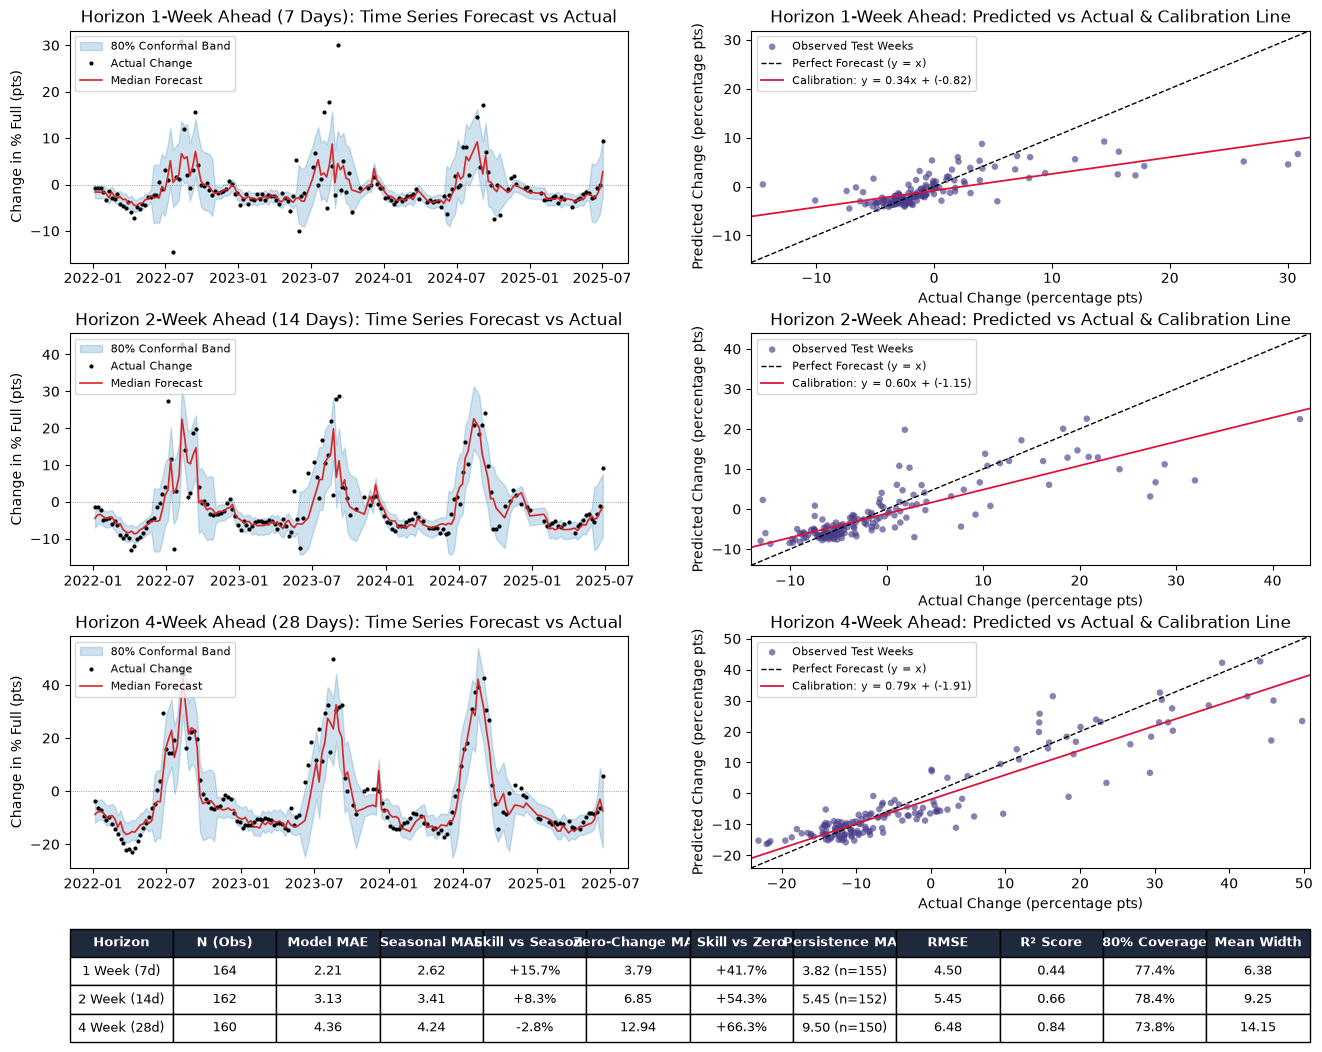

In [169]:
# (e) predicted vs actual (test period, chosen variant, conformal band) + calibration line + full 3-baseline metrics table
fig = plt.figure(figsize=(16, 13))
gs = fig.add_gridspec(4, 2, height_ratios=[1, 1, 1, 0.40], hspace=0.36, wspace=0.22)

table_data = []

for i, h in enumerate(HORIZONS):
    r = results[BEST_VARIANT][h]
    df_test = r["X_test"].copy()
    y = r["y_test"].values
    pred = r["med"]
    seas = r["seasonal"].values
    lo = r["c_lo"]
    hi = r["c_hi"]
    
    # Strictly genuinely observed target dates
    idx = df_test.index
    y_obs = y
    pred_obs = pred
    seas_obs = seas
    lo_obs = lo
    hi_obs = hi
    
    mae_obs = float(np.mean(np.abs(y_obs - pred_obs)))
    rmse_obs = float(np.sqrt(np.mean((y_obs - pred_obs)**2)))
    r2_obs = float(r2_score(y_obs, pred_obs))
    seas_mae_obs = float(np.mean(np.abs(y_obs - seas_obs)))
    zc_mae_obs = float(np.mean(np.abs(y_obs)))
    skill_seas = (1.0 - mae_obs / seas_mae_obs) * 100
    skill_zc = (1.0 - mae_obs / zc_mae_obs) * 100
    cov_obs = float(np.mean((y_obs >= lo_obs) & (y_obs <= hi_obs))) * 100
    w_obs = float(np.mean(hi_obs - lo_obs))
    
    # Persistence baseline (evaluated only where historical observation at t-h exists)
    past_h = pd.Series(df_test.index.map(test_mask) - (df_test.index - pd.Timedelta(weeks=h)).map(test_mask), index=df_test.index)
    valid_pers = past_h.notna().values
    mae_pers = float(np.mean(np.abs(y[valid_pers] - past_h.values[valid_pers])))
    n_pers = int(valid_pers.sum())
    
    table_data.append([
        f"{h} Week ({h*7}d)", f"{len(y_obs)}", f"{mae_obs:.2f}", f"{seas_mae_obs:.2f}",
        f"{skill_seas:+.1f}%", f"{zc_mae_obs:.2f}", f"+{skill_zc:.1f}%",
        f"{mae_pers:.2f} (n={n_pers})", f"{rmse_obs:.2f}", f"{r2_obs:.2f}", f"{cov_obs:.1f}%", f"{w_obs:.2f}"
    ])
    
    # Left Column: Time Series Panel (Preserved Temporal Structure & Conformal Uncertainty)
    ax_ts = fig.add_subplot(gs[i, 0])
    ax_ts.fill_between(idx, lo, hi, color="tab:blue", alpha=0.22, label=f"{int(CONFORMAL_LEVEL*100)}% Conformal Band")
    ax_ts.plot(idx, y, "k.", ms=4, label="Actual Change")
    ax_ts.plot(idx, pred, color="tab:red", lw=1.2, label="Median Forecast")
    ax_ts.axhline(0, color="gray", lw=0.6, ls=":")
    ax_ts.set_ylabel("Change in % Full (pts)")
    ax_ts.set_title(f"Horizon {h}-Week Ahead ({h*7} Days): Time Series Forecast vs Actual")
    ax_ts.legend(loc="upper left", fontsize=8)
    
    # Right Column: Predicted vs Actual Scatter with Calibration Line
    ax_sc = fig.add_subplot(gs[i, 1])
    ax_sc.scatter(y_obs, pred_obs, alpha=0.65, color="darkslateblue", edgecolors="none", s=22, label="Observed Test Weeks")
    
    lims = [min(y_obs.min(), pred_obs.min()) - 1, max(y_obs.max(), pred_obs.max()) + 1]
    ax_sc.plot(lims, lims, "k--", lw=1.0, label="Perfect Forecast (y = x)")
    
    cal_poly = np.polyfit(y_obs, pred_obs, 1)
    x_grid = np.linspace(lims[0], lims[1], 100)
    y_cal = np.polyval(cal_poly, x_grid)
    ax_sc.plot(x_grid, y_cal, color="crimson", lw=1.3, label=f"Calibration: y = {cal_poly[0]:.2f}x + ({cal_poly[1]:+.2f})")
    
    ax_sc.set_xlim(lims)
    ax_sc.set_ylim(lims)
    ax_sc.set_xlabel("Actual Change (percentage pts)")
    ax_sc.set_ylabel("Predicted Change (percentage pts)")
    ax_sc.set_title(f"Horizon {h}-Week Ahead: Predicted vs Actual & Calibration Line")
    ax_sc.legend(loc="upper left", fontsize=8)

# Bottom row: Summary Metrics Table spanning both columns
ax_tbl = fig.add_subplot(gs[3, :])
ax_tbl.axis("off")
col_labels = [
    "Horizon", "N (Obs)", "Model MAE", "Seasonal MAE", "Skill vs Seasonal",
    "Zero-Change MAE", "Skill vs Zero", "Persistence MAE", "RMSE", "R² Score", "80% Coverage", "Mean Width"
]
tbl = ax_tbl.table(cellText=table_data, colLabels=col_labels, loc="center", cellLoc="center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(9.5)
tbl.scale(1.0, 1.7)

for k in range(len(col_labels)):
    tbl[(0, k)].set_facecolor("#1e293b")
    tbl[(0, k)].set_text_props(color="white", weight="bold")

plt.savefig(OUT_DIR / "pred_vs_actual.png", dpi=130, bbox_inches="tight")
plt.show()

## Notes for the write-up
- Call the longest horizon **4 weeks** (28 days), not "30 days".
- **4-week horizon skill vs seasonal baseline:** On held-out observed data (2022–2025), the 4-week model has MAE 4.36 vs Seasonal MAE 4.24 (-2.8% skill). Seasonal climatology is slightly superior to gradient boosting at 4 weeks. Do not claim the model beats seasonality at every horizon; predictive value is concentrated in the 1-week (+15.7%) and 2-week (+8.3%) tactical horizons.
- **Strictly independent rolling backtest (2022–2025):** Model variant (`dam`) and hyperparameters were selected on pre-2022 data; evaluating the rolling backtest and warnings strictly on 2022–2025 ensures complete independence from model selection.
- River discharge is GloFAS *reanalysis* (naturalised flow, no dam operations). At prediction time use the Flood API's forecast/latest values for the same points.
- Hirakud monsoon changes depend on gate-release decisions the model cannot see – report monsoon skill honestly, including if it is ≤ 0.
- The *oracle* table shows what a perfect rain forecast could add; real forecasts will land between the real-model and oracle numbers.
- Pre-2013 `storage_bcm` was re-derived from level; only `pct_full` is used here, with `implied_capacity_bcm` stored in the model bundle for days-of-cover.